# House Price Prediction — Data Understanding & Research

**Assignment:** PRCP-1020  
**Dataset:** Ames Housing Dataset  
**Objective:** Understand the dataset, investigate data quality, explore relationships with sale prices, and experiment with predictive modeling approaches.

## Research workflow
1. Load and validate the raw dataset.
2. Investigate missing values and data quality.
3. Explore target and feature distributions.
4. Analyze relationships between housing features and `SalePrice`.
5. Identify preprocessing requirements and candidate models.
6. Record findings for the final submission notebook.

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Resolve the project root whether Jupyter starts here or in notebooks/
CURRENT_DIR = Path.cwd()
PROJECT_ROOT = (
    CURRENT_DIR.parent
    if CURRENT_DIR.name == "notebooks"
    else CURRENT_DIR
)

DATA_PATH = (
    PROJECT_ROOT
    / "data"
    / "raw"
    / "extracted"
    / "Data"
    / "data.csv"
)

sns.set_theme(style="whitegrid", context="notebook")
pd.set_option("display.max_columns", 100)
pd.set_option("display.max_rows", 100)
pd.set_option("display.float_format", lambda value: f"{value:,.2f}")

print("Project root:", PROJECT_ROOT.resolve())
print("Dataset path:", DATA_PATH.resolve())
print("Dataset exists:", DATA_PATH.exists())

Project root: C:\Vishal\house-price-prediction
Dataset path: C:\Vishal\house-price-prediction\data\raw\extracted\Data\data.csv
Dataset exists: True


In [2]:
if not DATA_PATH.exists():
    raise FileNotFoundError(
        f"Dataset not found: {DATA_PATH}\n"
        "Check the project root and extracted dataset location."
    )

df = pd.read_csv(DATA_PATH)

print(f"Rows: {df.shape[0]:,}")
print(f"Columns: {df.shape[1]:,}")

display(df.head())

Rows: 1,460
Columns: 81


,Id,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,LotConfig,LandSlope,Neighborhood,Condition1,Condition2,BldgType,HouseStyle,OverallQual,OverallCond,YearBuilt,YearRemodAdd,RoofStyle,RoofMatl,Exterior1st,Exterior2nd,MasVnrType,MasVnrArea,ExterQual,ExterCond,Foundation,BsmtQual,BsmtCond,BsmtExposure,BsmtFinType1,BsmtFinSF1,BsmtFinType2,BsmtFinSF2,BsmtUnfSF,TotalBsmtSF,Heating,HeatingQC,CentralAir,Electrical,1stFlrSF,2ndFlrSF,LowQualFinSF,GrLivArea,BsmtFullBath,BsmtHalfBath,FullBath,HalfBath,BedroomAbvGr,KitchenAbvGr,KitchenQual,TotRmsAbvGrd,Functional,Fireplaces,FireplaceQu,GarageType,GarageYrBlt,GarageFinish,GarageCars,GarageArea,GarageQual,GarageCond,PavedDrive,WoodDeckSF,OpenPorchSF,EnclosedPorch,3SsnPorch,ScreenPorch,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice
0,1,60,RL,65.00,8450,Pave,NaN,Reg,Lvl,AllPub,Inside,Gtl,CollgCr,Norm,Norm,1Fam,2Story,7,5,2003,2003,Gable,CompShg,VinylSd,VinylSd,BrkFace,196.00,Gd,TA,PConc,Gd,TA,No,GLQ,706,Unf,0,150,856,GasA,Ex,Y,SBrkr,856,854,0,1710,1,0,2,1,3,1,Gd,8,Typ,0,NaN,Attchd,"2,003.00",RFn,2,548,TA,TA,Y,0,61,0,0,0,0,NaN,NaN,NaN,0,2,2008,WD,Normal,208500
1,2,20,RL,80.00,9600,Pave,NaN,Reg,Lvl,AllPub,FR2,Gtl,Veenker,Feedr,Norm,1Fam,1Story,6,8,1976,1976,Gable,CompShg,MetalSd,MetalSd,NaN,0.00,TA,TA,CBlock,Gd,TA,Gd,ALQ,978,Unf,0,284,1262,GasA,Ex,Y,SBrkr,1262,0,0,1262,0,1,2,0,3,1,TA,6,Typ,1,TA,Attchd,"1,976.00",RFn,2,460,TA,TA,Y,298,0,0,0,0,0,NaN,NaN,NaN,0,5,2007,WD,Normal,181500
2,3,60,RL,68.00,11250,Pave,NaN,IR1,Lvl,AllPub,Inside,Gtl,CollgCr,Norm,Norm,1Fam,2Story,7,5,2001,2002,Gable,CompShg,VinylSd,VinylSd,BrkFace,162.00,Gd,TA,PConc,Gd,TA,Mn,GLQ,486,Unf,0,434,920,GasA,Ex,Y,SBrkr,920,866,0,1786,1,0,2,1,3,1,Gd,6,Typ,1,TA,Attchd,"2,001.00",RFn,2,608,TA,TA,Y,0,42,0,0,0,0,NaN,NaN,NaN,0,9,2008,WD,Normal,223500
3,4,70,RL,60.00,9550,Pave,NaN,IR1,Lvl,AllPub,Corner,Gtl,Crawfor,Norm,Norm,1Fam,2Story,7,5,1915,1970,Gable,CompShg,Wd Sdng,Wd Shng,NaN,0.00,TA,TA,BrkTil,TA,Gd,No,ALQ,216,Unf,0,540,756,GasA,Gd,Y,SBrkr,961,756,0,1717,1,0,1,0,3,1,Gd,7,Typ,1,Gd,Detchd,"1,998.00",Unf,3,642,TA,TA,Y,0,35,272,0,0,0,NaN,NaN,NaN,0,2,2006,WD,Abnorml,140000
4,5,60,RL,84.00,14260,Pave,NaN,IR1,Lvl,AllPub,FR2,Gtl,NoRidge,Norm,Norm,1Fam,2Story,8,5,2000,2000,Gable,CompShg,VinylSd,VinylSd,BrkFace,350.00,Gd,TA,PConc,Gd,TA,Av,GLQ,655,Unf,0,490,1145,GasA,Ex,Y,SBrkr,1145,1053,0,2198,1,0,2,1,4,1,Gd,9,Typ,1,TA,Attchd,"2,000.00",RFn,3,836,TA,TA,Y,192,84,0,0,0,0,NaN,NaN,NaN,0,12,2008,WD,Normal,250000


## 1. Dataset Structure and Data Quality

This section establishes the dataset's baseline characteristics before preprocessing. We will inspect column types, duplicate records, missing values, and the target variable. No rows or values will be modified in this section.

In [3]:
# 1.1 Dataset dimensions and memory usage
print(f"Number of rows: {df.shape[0]:,}")
print(f"Number of columns: {df.shape[1]:,}")
print(f"Memory usage: {df.memory_usage(deep=True).sum() / 1024**2:.2f} MB")

# 1.2 Column types
dtype_summary = (
    df.dtypes.astype(str)
    .value_counts()
    .rename_axis("Data type")
    .reset_index(name="Number of columns")
)

display(dtype_summary)

# 1.3 Duplicate checks
print("Duplicate rows:", df.duplicated().sum())
print("Duplicate Id values:", df["Id"].duplicated().sum())

# 1.4 Target validation
print("Missing SalePrice values:", df["SalePrice"].isna().sum())
print("SalePrice values <= 0:", (df["SalePrice"] <= 0).sum())

display(df["SalePrice"].describe().to_frame().T)

Number of rows: 1,460
Number of columns: 81
Memory usage: 3.43 MB


,Data type,Number of columns
0,str,43
1,int64,35
2,float64,3


Duplicate rows: 0
Duplicate Id values: 0
Missing SalePrice values: 0
SalePrice values <= 0: 0


,count,mean,std,min,25%,50%,75%,max
SalePrice,"1,460.00","180,921.20","79,442.50","34,900.00","129,975.00","163,000.00","214,000.00","755,000.00"


## 2. Missing-Value Analysis

Missing values will be examined by count and percentage. In housing datasets, some missing entries may represent the absence of a feature (such as a pool or alley) rather than unknown information. We will investigate these cases before choosing an imputation strategy.

In [4]:
# Count and percentage of missing values by column
missing_summary = pd.DataFrame({
    "missing_count": df.isna().sum(),
    "missing_percent": df.isna().mean() * 100,
})

missing_summary = (
    missing_summary[missing_summary["missing_count"] > 0]
    .sort_values("missing_percent", ascending=False)
)

display(missing_summary.round(2))

print(f"Columns with missing values: {len(missing_summary)}")
print(f"Total missing cells: {int(df.isna().sum().sum()):,}")

,missing_count,missing_percent
PoolQC,1453,99.52
MiscFeature,1406,96.30
Alley,1369,93.77
Fence,1179,80.75
MasVnrType,872,59.73
FireplaceQu,690,47.26
LotFrontage,259,17.74
GarageType,81,5.55
GarageYrBlt,81,5.55
GarageFinish,81,5.55


Columns with missing values: 19
Total missing cells: 7,829


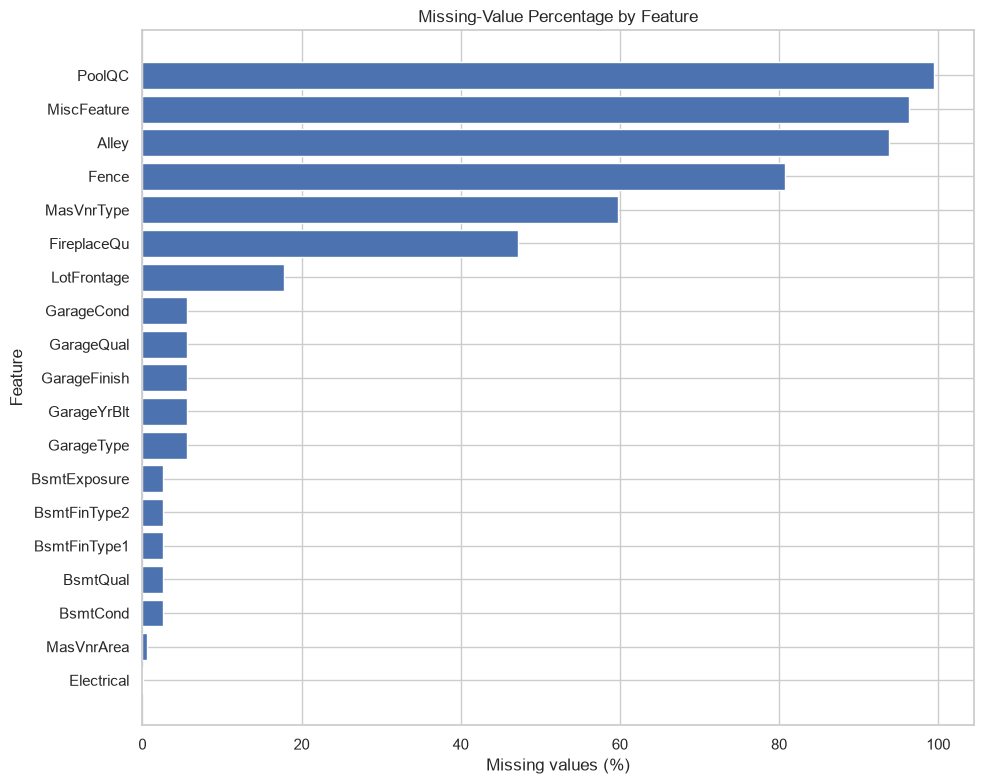

In [5]:
# Missing-value percentage by column
missing_plot = missing_summary.sort_values(
    "missing_percent",
    ascending=True
)

plt.figure(figsize=(10, 8))
plt.barh(
    missing_plot.index,
    missing_plot["missing_percent"]
)
plt.xlabel("Missing values (%)")
plt.ylabel("Feature")
plt.title("Missing-Value Percentage by Feature")
plt.tight_layout()
plt.show()

In [6]:
display(
    missing_summary
    .sort_values("missing_percent", ascending=False)
    .head(20)
    .round(2)
)

,missing_count,missing_percent
PoolQC,1453,99.52
MiscFeature,1406,96.30
Alley,1369,93.77
Fence,1179,80.75
MasVnrType,872,59.73
FireplaceQu,690,47.26
LotFrontage,259,17.74
GarageType,81,5.55
GarageYrBlt,81,5.55
GarageFinish,81,5.55


In [7]:
# Inspect selected rows where important features are missing
features_to_check = [
    "PoolQC", "MiscFeature", "Alley", "Fence",
    "FireplaceQu", "GarageType", "GarageYrBlt",
    "BsmtQual", "BsmtExposure", "MasVnrType",
]

display(
    df.loc[
        df[features_to_check].isna().any(axis=1),
        features_to_check + ["SalePrice"]
    ].head(15)
)

,PoolQC,MiscFeature,Alley,Fence,FireplaceQu,GarageType,GarageYrBlt,BsmtQual,BsmtExposure,MasVnrType,SalePrice
0,NaN,NaN,NaN,NaN,NaN,Attchd,"2,003.00",Gd,No,BrkFace,208500
1,NaN,NaN,NaN,NaN,TA,Attchd,"1,976.00",Gd,Gd,NaN,181500
2,NaN,NaN,NaN,NaN,TA,Attchd,"2,001.00",Gd,Mn,BrkFace,223500
3,NaN,NaN,NaN,NaN,Gd,Detchd,"1,998.00",TA,No,NaN,140000
4,NaN,NaN,NaN,NaN,TA,Attchd,"2,000.00",Gd,Av,BrkFace,250000
5,NaN,Shed,NaN,MnPrv,NaN,Attchd,"1,993.00",Gd,No,NaN,143000
6,NaN,NaN,NaN,NaN,Gd,Attchd,"2,004.00",Ex,Av,Stone,307000
7,NaN,Shed,NaN,NaN,TA,Attchd,"1,973.00",Gd,Mn,Stone,200000
8,NaN,NaN,NaN,NaN,TA,Detchd,"1,931.00",TA,No,NaN,129900
9,NaN,NaN,NaN,NaN,TA,Attchd,"1,939.00",TA,No,NaN,118000


In [8]:
# Compare missing categorical fields with related numeric or indicator fields.

checks = {
    "PoolQC": ["PoolArea"],
    "GarageType": ["GarageCars", "GarageArea", "GarageYrBlt"],
    "BsmtQual": ["TotalBsmtSF", "BsmtFinSF1", "BsmtUnfSF"],
    "FireplaceQu": ["Fireplaces"],
    "MasVnrType": ["MasVnrArea"],
}

for missing_feature, related_features in checks.items():
    print(f"\n{'=' * 70}")
    print(f"{missing_feature} is missing")
    print("=" * 70)

    missing_mask = df[missing_feature].isna()

    print(f"Rows with missing {missing_feature}: {missing_mask.sum()}")

    display(
        df.loc[missing_mask, related_features]
        .describe(include="all")
        .T
    )

    for related_feature in related_features:
        if pd.api.types.is_numeric_dtype(df[related_feature]):
            print(
                f"{related_feature} == 0 among missing "
                f"{missing_feature}: "
                f"{(df.loc[missing_mask, related_feature] == 0).sum()} "
                f"/ {missing_mask.sum()}"
            )


PoolQC is missing
Rows with missing PoolQC: 1453


,count,mean,std,min,25%,50%,75%,max
PoolArea,"1,453.00",0.00,0.00,0.00,0.00,0.00,0.00,0.00


PoolArea == 0 among missing PoolQC: 1453 / 1453

GarageType is missing
Rows with missing GarageType: 81


,count,mean,std,min,25%,50%,75%,max
GarageCars,81.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00
GarageArea,81.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00
GarageYrBlt,0.00,NaN,NaN,NaN,NaN,NaN,NaN,NaN


GarageCars == 0 among missing GarageType: 81 / 81
GarageArea == 0 among missing GarageType: 81 / 81
GarageYrBlt == 0 among missing GarageType: 0 / 81

BsmtQual is missing
Rows with missing BsmtQual: 37


,count,mean,std,min,25%,50%,75%,max
TotalBsmtSF,37.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00
BsmtFinSF1,37.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00
BsmtUnfSF,37.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00


TotalBsmtSF == 0 among missing BsmtQual: 37 / 37
BsmtFinSF1 == 0 among missing BsmtQual: 37 / 37
BsmtUnfSF == 0 among missing BsmtQual: 37 / 37

FireplaceQu is missing
Rows with missing FireplaceQu: 690


,count,mean,std,min,25%,50%,75%,max
Fireplaces,690.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00


Fireplaces == 0 among missing FireplaceQu: 690 / 690

MasVnrType is missing
Rows with missing MasVnrType: 872


,count,mean,std,min,25%,50%,75%,max
MasVnrArea,864.00,1.09,18.57,0.00,0.00,0.00,0.00,344.00


MasVnrArea == 0 among missing MasVnrType: 859 / 872


In [9]:
missing_pattern = pd.DataFrame({
    "GarageType_missing": df["GarageType"].isna(),
    "GarageYrBlt_missing": df["GarageYrBlt"].isna(),
    "GarageFinish_missing": df["GarageFinish"].isna(),
    "BsmtQual_missing": df["BsmtQual"].isna(),
    "BsmtCond_missing": df["BsmtCond"].isna(),
    "PoolQC_missing": df["PoolQC"].isna(),
    "FireplaceQu_missing": df["FireplaceQu"].isna(),
})

display(
    missing_pattern
    .value_counts()
    .rename("row_count")
    .reset_index()
    .sort_values("row_count", ascending=False)
    .head(15)
)

,GarageType_missing,GarageYrBlt_missing,GarageFinish_missing,BsmtQual_missing,BsmtCond_missing,PoolQC_missing,FireplaceQu_missing,row_count
0,False,False,False,False,False,True,False,746
1,False,False,False,False,False,True,True,596
2,True,True,True,False,False,True,True,66
3,False,False,False,True,True,True,True,22
4,True,True,True,False,False,True,False,8
5,False,False,False,True,True,True,False,8
6,False,False,False,False,False,False,False,7
7,True,True,True,True,True,True,True,6
8,True,True,True,True,True,True,False,1


In [10]:
masvnr_review = df.loc[
    df["MasVnrType"].isna()
    & (
        df["MasVnrArea"].isna()
        | (df["MasVnrArea"] > 0)
    ),
    ["Id", "MasVnrType", "MasVnrArea", "OverallQual", "Neighborhood", "SalePrice"]
].sort_values("MasVnrArea", na_position="last")

display(masvnr_review)
print("Rows requiring review:", len(masvnr_review))

,Id,MasVnrType,MasVnrArea,OverallQual,Neighborhood,SalePrice
773,774,NaN,1.00,5,NAmes,114500
1230,1231,NaN,1.00,5,Sawyer,190000
624,625,NaN,288.00,6,NWAmes,165150
1334,1335,NaN,312.00,5,BrDale,125000
1300,1301,NaN,344.00,7,Gilbert,225000
234,235,NaN,NaN,6,Gilbert,216500
529,530,NaN,NaN,6,Crawfor,200624
650,651,NaN,NaN,7,Somerst,205950
936,937,NaN,NaN,7,SawyerW,184900
973,974,NaN,NaN,7,Somerst,182000


Rows requiring review: 13


In [11]:
quality_checks = {
    "Duplicate complete rows": int(df.duplicated().sum()),
    "Duplicate Id values": int(df["Id"].duplicated().sum()),
    "Missing SalePrice values": int(df["SalePrice"].isna().sum()),
    "Non-positive SalePrice values": int((df["SalePrice"] <= 0).sum()),
    "Minimum sale year": int(df["YrSold"].min()),
    "Maximum sale year": int(df["YrSold"].max()),
}

display(
    pd.DataFrame(
        list(quality_checks.items()),
        columns=["Check", "Result"]
    )
)

,Check,Result
0,Duplicate complete rows,0
1,Duplicate Id values,0
2,Missing SalePrice values,0
3,Non-positive SalePrice values,0
4,Minimum sale year,2006
5,Maximum sale year,2010


## 3. Target Variable Analysis — SalePrice

We examine the distribution, skewness, and extreme values of the target variable. The goal is to understand price variability and identify modeling considerations, not to remove expensive properties automatically.

SalePrice skewness: 1.883
SalePrice kurtosis: 6.536


,count,mean,std,min,25%,50%,75%,max
SalePrice,"1,460.00","180,921.20","79,442.50","34,900.00","129,975.00","163,000.00","214,000.00","755,000.00"


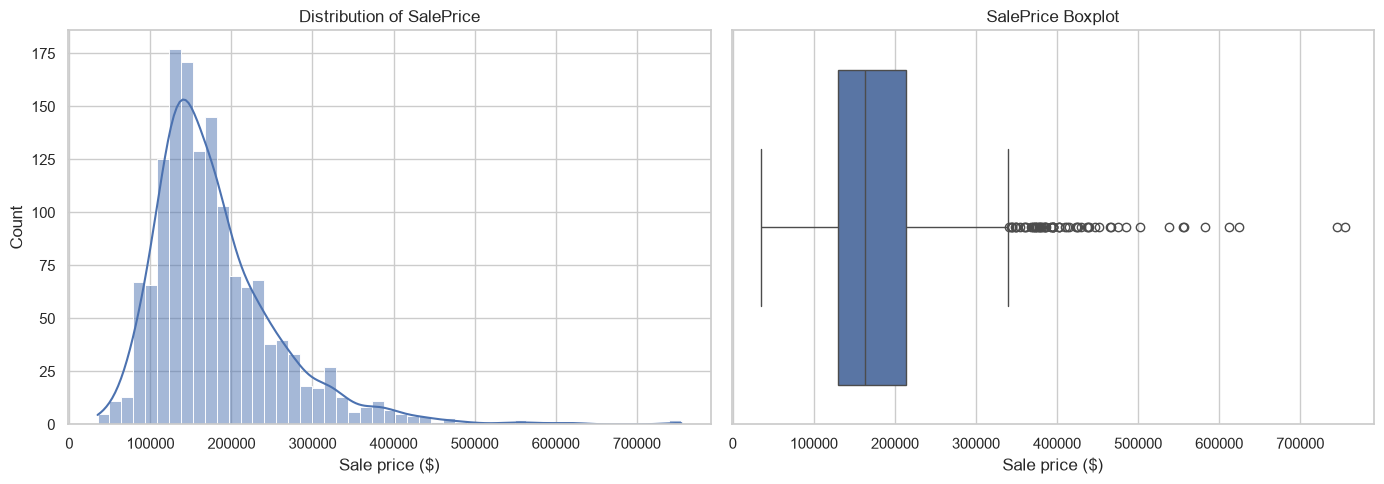

In [12]:
# Summary statistics
print("SalePrice skewness:", round(df["SalePrice"].skew(), 3))
print("SalePrice kurtosis:", round(df["SalePrice"].kurtosis(), 3))

display(df["SalePrice"].describe().to_frame().T)

# Distribution and boxplot
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.histplot(
    df["SalePrice"],
    kde=True,
    ax=axes[0]
)
axes[0].set_title("Distribution of SalePrice")
axes[0].set_xlabel("Sale price ($)")

sns.boxplot(
    x=df["SalePrice"],
    ax=axes[1]
)
axes[1].set_title("SalePrice Boxplot")
axes[1].set_xlabel("Sale price ($)")

plt.tight_layout()
plt.show()

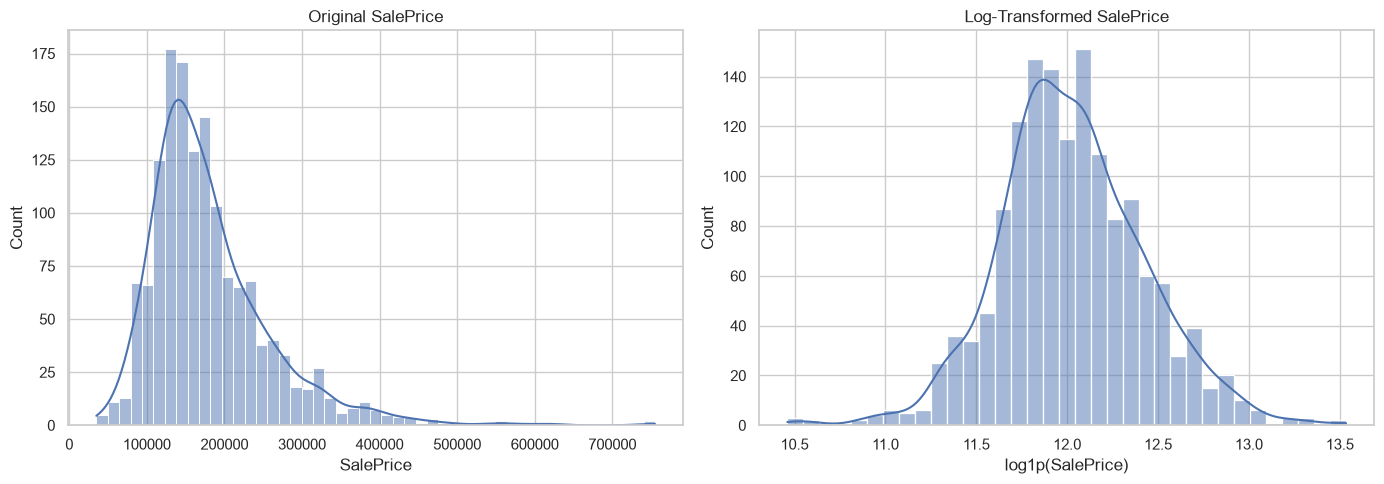

Original skewness: 1.883
Log-transformed skewness: 0.121


In [13]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.histplot(
    df["SalePrice"],
    kde=True,
    ax=axes[0]
)
axes[0].set_title("Original SalePrice")

sns.histplot(
    np.log1p(df["SalePrice"]),
    kde=True,
    ax=axes[1]
)
axes[1].set_title("Log-Transformed SalePrice")
axes[1].set_xlabel("log1p(SalePrice)")

plt.tight_layout()
plt.show()

print("Original skewness:", round(df["SalePrice"].skew(), 3))
print(
    "Log-transformed skewness:",
    round(np.log1p(df["SalePrice"]).skew(), 3)
)

### Target distribution findings

The target variable `SalePrice` is positively skewed, with a skewness of 1.883 and kurtosis of 6.536. Its mean ($180,921) exceeds its median ($163,000), indicating that expensive properties pull the distribution toward higher values.

Applying `log1p` reduces skewness to 0.121, producing a distribution that is much closer to symmetric. Therefore, target transformation is a promising modeling experiment. Its usefulness will be evaluated using validation metrics, with predictions converted back to dollar prices when required.

## 4. Relationship Between Features and Sale Price

We investigate how property quality, living area, and construction year relate to `SalePrice`. These are exploratory associations, not proof of causation.

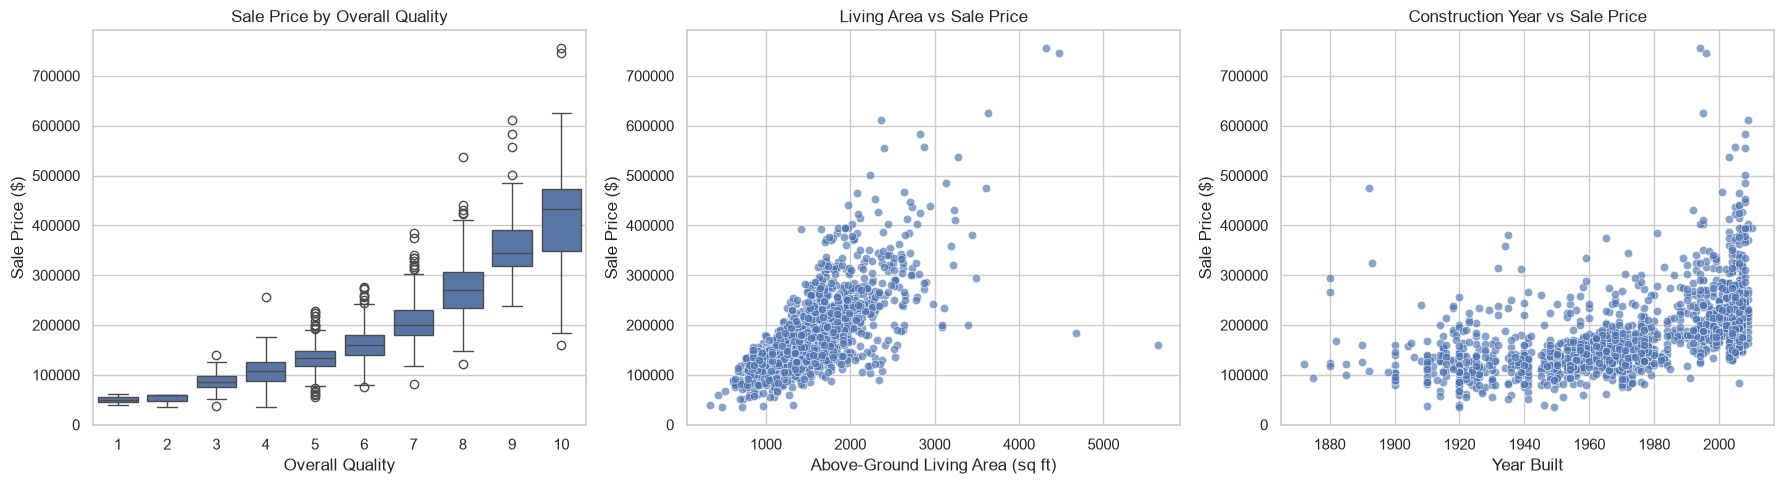

In [14]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

sns.boxplot(
    data=df,
    x="OverallQual",
    y="SalePrice",
    ax=axes[0]
)
axes[0].set_title("Sale Price by Overall Quality")
axes[0].set_xlabel("Overall Quality")
axes[0].set_ylabel("Sale Price ($)")

sns.scatterplot(
    data=df,
    x="GrLivArea",
    y="SalePrice",
    alpha=0.65,
    ax=axes[1]
)
axes[1].set_title("Living Area vs Sale Price")
axes[1].set_xlabel("Above-Ground Living Area (sq ft)")
axes[1].set_ylabel("Sale Price ($)")

sns.scatterplot(
    data=df,
    x="YearBuilt",
    y="SalePrice",
    alpha=0.65,
    ax=axes[2]
)
axes[2].set_title("Construction Year vs Sale Price")
axes[2].set_xlabel("Year Built")
axes[2].set_ylabel("Sale Price ($)")

plt.tight_layout()
plt.show()

In [15]:
numeric_relationships = (
    df[["OverallQual", "GrLivArea", "YearBuilt", "SalePrice"]]
    .corr(numeric_only=True)["SalePrice"]
    .drop("SalePrice")
    .sort_values(ascending=False)
)

display(
    numeric_relationships
    .rename("Pearson correlation with SalePrice")
    .to_frame()
)

print("\nMedian sale price by OverallQual:")
display(
    df.groupby("OverallQual", observed=True)["SalePrice"]
    .agg(["count", "median", "mean"])
    .round(2)
)

,Pearson correlation with SalePrice
OverallQual,0.79
GrLivArea,0.71
YearBuilt,0.52



Median sale price by OverallQual:


,count,median,mean
OverallQual,,,
1,2,"50,150.00","50,150.00"
2,3,"60,000.00","51,770.33"
3,20,"86,250.00","87,473.75"
4,116,"108,000.00","108,420.66"
5,397,"133,000.00","133,523.35"
6,374,"160,000.00","161,603.03"
7,319,"200,141.00","207,716.42"
8,168,"269,750.00","274,735.54"
9,43,"345,000.00","367,513.02"


## 5. Neighborhood and Sale Price

We compare sale prices across neighborhoods to identify geographic price differences within the Ames housing dataset. These comparisons are descriptive and do not isolate the independent effect of location.

,count,median,mean
Neighborhood,,,
NridgHt,77,"315,000.00","316,270.62"
NoRidge,41,"301,500.00","335,295.32"
StoneBr,25,"278,000.00","310,499.00"
Timber,38,"228,475.00","242,247.45"
Somerst,86,"225,500.00","225,379.84"
Veenker,11,"218,000.00","238,772.73"
Crawfor,51,"200,624.00","210,624.73"
ClearCr,28,"200,250.00","212,565.43"
CollgCr,150,"197,200.00","197,965.77"


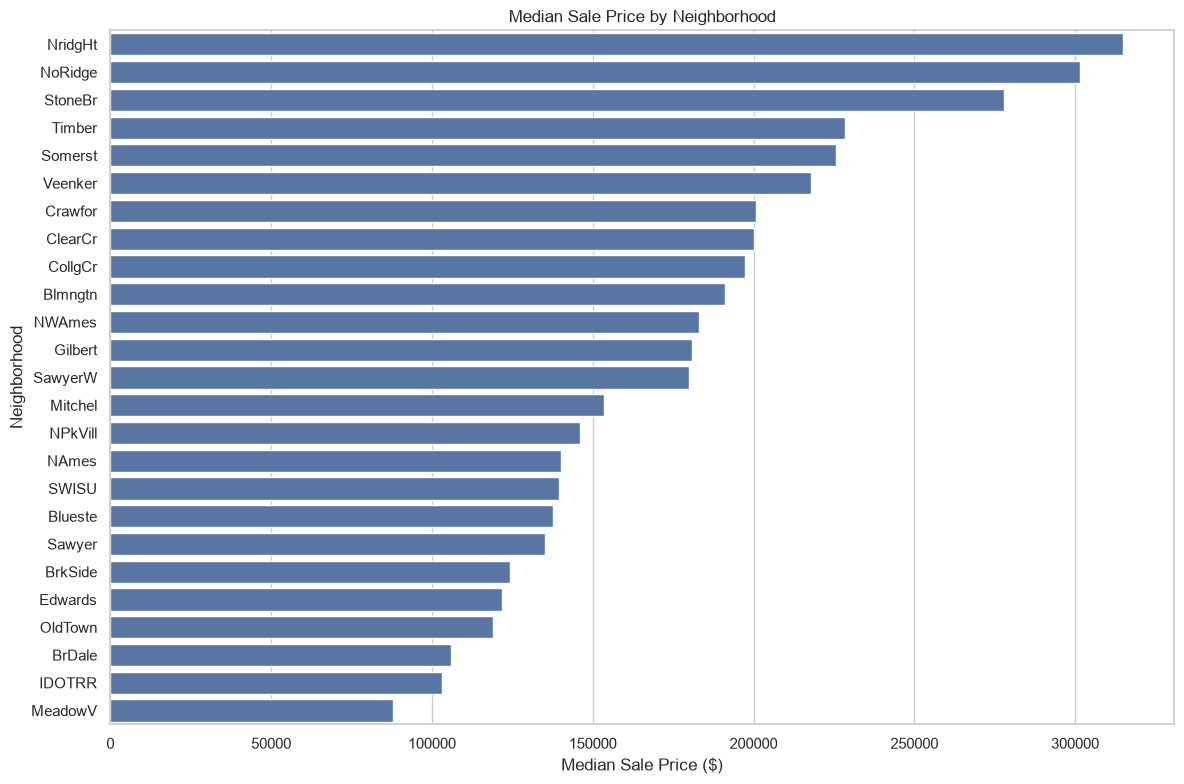

In [16]:
neighborhood_prices = (
    df.groupby("Neighborhood", observed=True)["SalePrice"]
    .agg(["count", "median", "mean"])
    .sort_values("median", ascending=False)
)

display(neighborhood_prices.round(2))

plt.figure(figsize=(12, 8))

sns.barplot(
    data=neighborhood_prices.reset_index(),
    x="median",
    y="Neighborhood"
)

plt.title("Median Sale Price by Neighborhood")
plt.xlabel("Median Sale Price ($)")
plt.ylabel("Neighborhood")
plt.tight_layout()
plt.show()

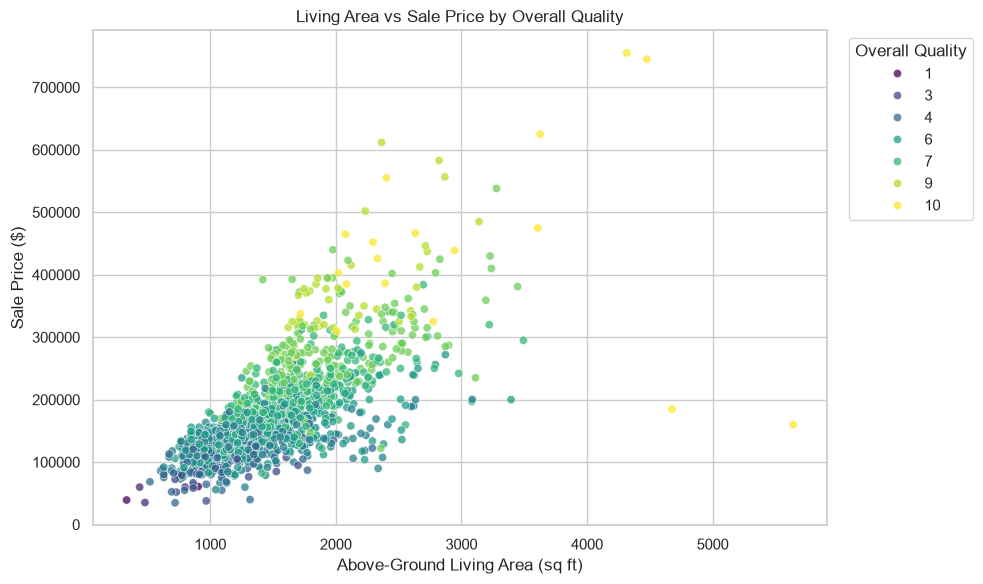

In [17]:
plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=df,
    x="GrLivArea",
    y="SalePrice",
    hue="OverallQual",
    palette="viridis",
    alpha=0.75
)

plt.title("Living Area vs Sale Price by Overall Quality")
plt.xlabel("Above-Ground Living Area (sq ft)")
plt.ylabel("Sale Price ($)")
plt.legend(title="Overall Quality", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.show()

In [18]:
# Spearman correlation can capture monotonic relationships
# without requiring them to be perfectly linear.
features = ["OverallQual", "GrLivArea", "YearBuilt", "LotArea", "GarageCars"]

correlation_summary = pd.DataFrame({
    "Pearson": df[features + ["SalePrice"]].corr(method="pearson")["SalePrice"],
    "Spearman": df[features + ["SalePrice"]].corr(method="spearman")["SalePrice"],
}).drop(index="SalePrice").sort_values("Pearson", ascending=False)

display(correlation_summary.round(3))

,Pearson,Spearman
OverallQual,0.79,0.81
GrLivArea,0.71,0.73
GarageCars,0.64,0.69
YearBuilt,0.52,0.65
LotArea,0.26,0.46


In [19]:
# IQR-based flags for exploration only
outlier_summary = {}

for column in ["SalePrice", "GrLivArea", "LotArea"]:
    q1 = df[column].quantile(0.25)
    q3 = df[column].quantile(0.75)
    iqr = q3 - q1

    lower = q1 - 1.5 * iqr
    upper = q3 + 1.5 * iqr
    mask = (df[column] < lower) | (df[column] > upper)

    outlier_summary[column] = {
        "lower_fence": lower,
        "upper_fence": upper,
        "flagged_count": int(mask.sum()),
    }

display(pd.DataFrame(outlier_summary).T.round(2))

# Inspect the largest living areas
display(
    df.nlargest(10, "GrLivArea")[
        ["Id", "Neighborhood", "OverallQual", "GrLivArea", "SalePrice"]
    ]
)

,lower_fence,upper_fence,flagged_count
SalePrice,"3,937.50","340,037.50",61.00
GrLivArea,158.62,"2,747.62",31.00
LotArea,"1,481.50","17,673.50",69.00


,Id,Neighborhood,OverallQual,GrLivArea,SalePrice
1298,1299,Edwards,10,5642,160000
523,524,Edwards,10,4676,184750
1182,1183,NoRidge,10,4476,745000
691,692,NoRidge,10,4316,755000
1169,1170,NoRidge,10,3627,625000
185,186,OldTown,10,3608,475000
304,305,OldTown,7,3493,295000
1268,1269,Crawfor,8,3447,381000
635,636,SWISU,6,3395,200000
769,770,StoneBr,8,3279,538000


### Interim research findings

- Overall quality, above-ground living area, and construction year show positive associations with sale price.
- Neighborhood median sale prices vary substantially across the dataset.
- Neighborhood comparisons are descriptive and may reflect differences in house quality, size, and age.
- Potential outliers will be investigated rather than removed automatically.
- Pearson and Spearman correlations will be compared to understand both linear and monotonic associations.

In [20]:
# Inspect the highest SalePrice observations
display(
    df.nlargest(15, "SalePrice")[
        [
            "Id",
            "Neighborhood",
            "OverallQual",
            "OverallCond",
            "GrLivArea",
            "YearBuilt",
            "GarageCars",
            "SalePrice",
        ]
    ]
)

,Id,Neighborhood,OverallQual,OverallCond,GrLivArea,YearBuilt,GarageCars,SalePrice
691,692,NoRidge,10,6,4316,1994,3,755000
1182,1183,NoRidge,10,5,4476,1996,3,745000
1169,1170,NoRidge,10,5,3627,1995,3,625000
898,899,NridgHt,9,5,2364,2009,3,611657
803,804,NridgHt,9,5,2822,2008,3,582933
1046,1047,StoneBr,9,5,2868,2005,3,556581
440,441,NridgHt,10,5,2402,2008,3,555000
769,770,StoneBr,8,5,3279,2003,3,538000
178,179,StoneBr,9,5,2234,2008,3,501837
798,799,NridgHt,9,5,3140,2008,3,485000


In [21]:
# Flag unusually large homes using the IQR upper fence
q1 = df["GrLivArea"].quantile(0.25)
q3 = df["GrLivArea"].quantile(0.75)
iqr = q3 - q1
upper_fence = q3 + 1.5 * iqr

large_home_review = df.loc[
    (df["GrLivArea"] > upper_fence)
].sort_values("SalePrice")[
    [
        "Id",
        "Neighborhood",
        "OverallQual",
        "OverallCond",
        "GrLivArea",
        "YearBuilt",
        "GarageCars",
        "SalePrice",
    ]
]

display(large_home_review.head(15))

,Id,Neighborhood,OverallQual,OverallCond,GrLivArea,YearBuilt,GarageCars,SalePrice
1298,1299,Edwards,10,5,5642,2008,2,160000
523,524,Edwards,10,5,4676,2007,3,184750
1031,1032,SWISU,7,3,3082,1920,2,197000
635,636,SWISU,6,7,3395,1914,0,200000
1173,1174,ClearCr,5,6,3086,1946,0,200500
197,198,NAmes,8,4,3112,1918,2,235000
324,325,NAmes,7,7,2978,1967,2,242000
1386,1387,NWAmes,7,5,2784,1978,2,250000
1328,1329,OldTown,6,7,2792,1920,2,256000
961,962,NWAmes,6,7,2872,1977,2,272000


In [22]:
categorical_features = [
    "ExterQual",
    "KitchenQual",
    "SaleCondition",
]

for feature in categorical_features:
    summary = (
        df.groupby(feature, observed=True)["SalePrice"]
        .agg(["count", "median", "mean"])
        .sort_values("median", ascending=False)
    )

    print(f"\nSalePrice by {feature}")
    display(summary.round(2))


SalePrice by ExterQual


,count,median,mean
ExterQual,,,
Ex,52,"364,606.50","367,360.96"
Gd,488,"220,000.00","231,633.51"
TA,906,"139,450.00","144,341.31"
Fa,14,"82,250.00","87,985.21"



SalePrice by KitchenQual


,count,median,mean
KitchenQual,,,
Ex,100,"316,750.00","328,554.67"
Gd,586,"201,400.00","212,116.02"
TA,735,"137,000.00","139,962.51"
Fa,39,"115,000.00","105,565.21"



SalePrice by SaleCondition


,count,median,mean
SaleCondition,,,
Partial,125,"244,600.00","272,291.75"
Normal,1198,"160,000.00","175,202.22"
Alloca,12,"148,145.00","167,377.42"
Family,20,"140,500.00","149,600.00"
Abnorml,101,"130,000.00","146,526.62"
AdjLand,4,"104,000.00","104,125.00"


### Additional Findings: High-Value Homes, Outliers, and Quality Features

**Highest-priced properties**
- The 15 highest-priced properties generally have high overall quality ratings and three-car garage capacity.
- Several are located in NridgHt, NoRidge, and StoneBr.
- A high-quality older property in OldTown demonstrates that age alone does not determine sale price.
- These observations suggest that property quality, location, living area, and garage capacity may be useful predictors.

**Unusually large properties**
- The IQR method identifies unusually large living areas, but an IQR flag does not establish that a record is erroneous.
- Properties with Id 1299 and Id 524 have exceptionally large living areas but comparatively low sale prices.
- These observations should be retained during initial analysis and investigated during model evaluation. Their influence can be assessed by comparing validation performance with and without them, without assuming removal is justified.

**Categorical feature relationships**
- Median sale price increases consistently across the observed exterior-quality categories, from Fa to Ex.
- Median sale price also increases consistently across the observed kitchen-quality categories, from Fa to Ex.
- SaleCondition categories have different price distributions. Partial has the highest median in this dataset, while AdjLand has a low median based on only four observations.
- Small category counts should be considered when interpreting these summaries.

**Interim conclusion**
OverallQual, GrLivArea, neighborhood, exterior quality, and kitchen quality are promising features for further modeling. These relationships are descriptive and must be evaluated using a validation strategy before drawing conclusions about predictive performance.

In [23]:
# Inspect categorical columns and the number of unique values in each.
categorical_columns = df.select_dtypes(
    include=["object", "category"]
).columns.tolist()

categorical_summary = pd.DataFrame({
    "unique_values": df[categorical_columns].nunique(dropna=False),
    "missing_count": df[categorical_columns].isna().sum(),
}).sort_values("unique_values")

display(categorical_summary)

C:\Users\LOQ\AppData\Local\Temp\ipykernel_21372\3029783659.py:2: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/dev/user_guide/migration.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_columns = df.select_dtypes(


,unique_values,missing_count
Street,2,0
Utilities,2,0
CentralAir,2,0
LandSlope,3,0
Alley,3,1369
PavedDrive,3,0
MasVnrType,4,872
LandContour,4,0
ExterQual,4,0
KitchenQual,4,0


### Categorical Feature Structure

The dataset contains 43 categorical columns.

- Most categorical features have between 2 and 9 distinct values, making them suitable candidates for one-hot encoding in a baseline machine-learning pipeline.
- `Neighborhood` has 25 distinct values, while `Exterior1st` and `Exterior2nd` have 15 and 16, respectively. These higher-cardinality features may produce more encoded columns.
- Several categorical features have substantial missingness, including `PoolQC`, `MiscFeature`, `Alley`, `Fence`, `MasVnrType`, and `FireplaceQu`.
- In this dataset, some missing categorical values appear to represent the absence of a property feature rather than an unknown measurement. This must be handled deliberately during preprocessing.
- `Electrical` has only one missing value, which requires a separate, simple treatment.
- The number of distinct values includes missingness because the summary uses `nunique(dropna=False)`.

**Preprocessing implication:** Missing-value handling and categorical encoding should be implemented inside a scikit-learn preprocessing pipeline. This will allow transformations to be fitted only on training data and help prevent data leakage during validation.

In [24]:
# Summarize numerical features, excluding the identifier and target.
numerical_features = (
    df.select_dtypes(include=["number"])
    .columns
    .difference(["Id", "SalePrice"])
    .tolist()
)

numerical_summary = pd.DataFrame({
    "dtype": df[numerical_features].dtypes.astype(str),
    "unique_values": df[numerical_features].nunique(),
    "missing_count": df[numerical_features].isna().sum(),
    "mean": df[numerical_features].mean(),
    "median": df[numerical_features].median(),
    "std": df[numerical_features].std(),
    "min": df[numerical_features].min(),
    "max": df[numerical_features].max(),
})

display(numerical_summary.round(2))
print("Numerical predictor count:", len(numerical_features))

,dtype,unique_values,missing_count,mean,median,std,min,max
1stFlrSF,int64,753,0,"1,162.63","1,087.00",386.59,334.00,"4,692.00"
2ndFlrSF,int64,417,0,346.99,0.00,436.53,0.00,"2,065.00"
3SsnPorch,int64,20,0,3.41,0.00,29.32,0.00,508.00
BedroomAbvGr,int64,8,0,2.87,3.00,0.82,0.00,8.00
BsmtFinSF1,int64,637,0,443.64,383.50,456.10,0.00,"5,644.00"
BsmtFinSF2,int64,144,0,46.55,0.00,161.32,0.00,"1,474.00"
BsmtFullBath,int64,4,0,0.43,0.00,0.52,0.00,3.00
BsmtHalfBath,int64,3,0,0.06,0.00,0.24,0.00,2.00
BsmtUnfSF,int64,780,0,567.24,477.50,441.87,0.00,"2,336.00"
EnclosedPorch,int64,120,0,21.95,0.00,61.12,0.00,552.00


Numerical predictor count: 36


### Numerical Feature Analysis

The dataset contains 36 numerical predictors, excluding the identifier (`Id`) and target (`SalePrice`).

**Missing values**
- `LotFrontage`: 259 missing values.
- `GarageYrBlt`: 81 missing values.
- `MasVnrArea`: 8 missing values.
- Missing values will be handled within the preprocessing pipeline to avoid data leakage.

**Distributions and extreme values**
- `LotArea` and `GrLivArea` have wide ranges, suggesting that distribution checks and validation-based evaluation of transformations may be useful.
- Several area-related variables have median values of zero, indicating that many properties lack the corresponding feature.
- Extreme values will be investigated rather than automatically removed.

**Feature interpretation**
- `MSSubClass` is numerically encoded but represents a building-class category.
- `MoSold` and `YrSold` represent the month and year of sale.
- `YearBuilt`, `YearRemodAdd`, and `GarageYrBlt` may provide information about property age and renovation history.

**Modeling implications**
- Numerical and categorical predictors will require separate preprocessing steps.
- Missing numerical values can initially be imputed using training-set medians.
- Categorical variables will need appropriate missing-value handling and encoding.
- Feature transformations and outlier treatment should be evaluated using validation performance rather than assumed to improve the model.

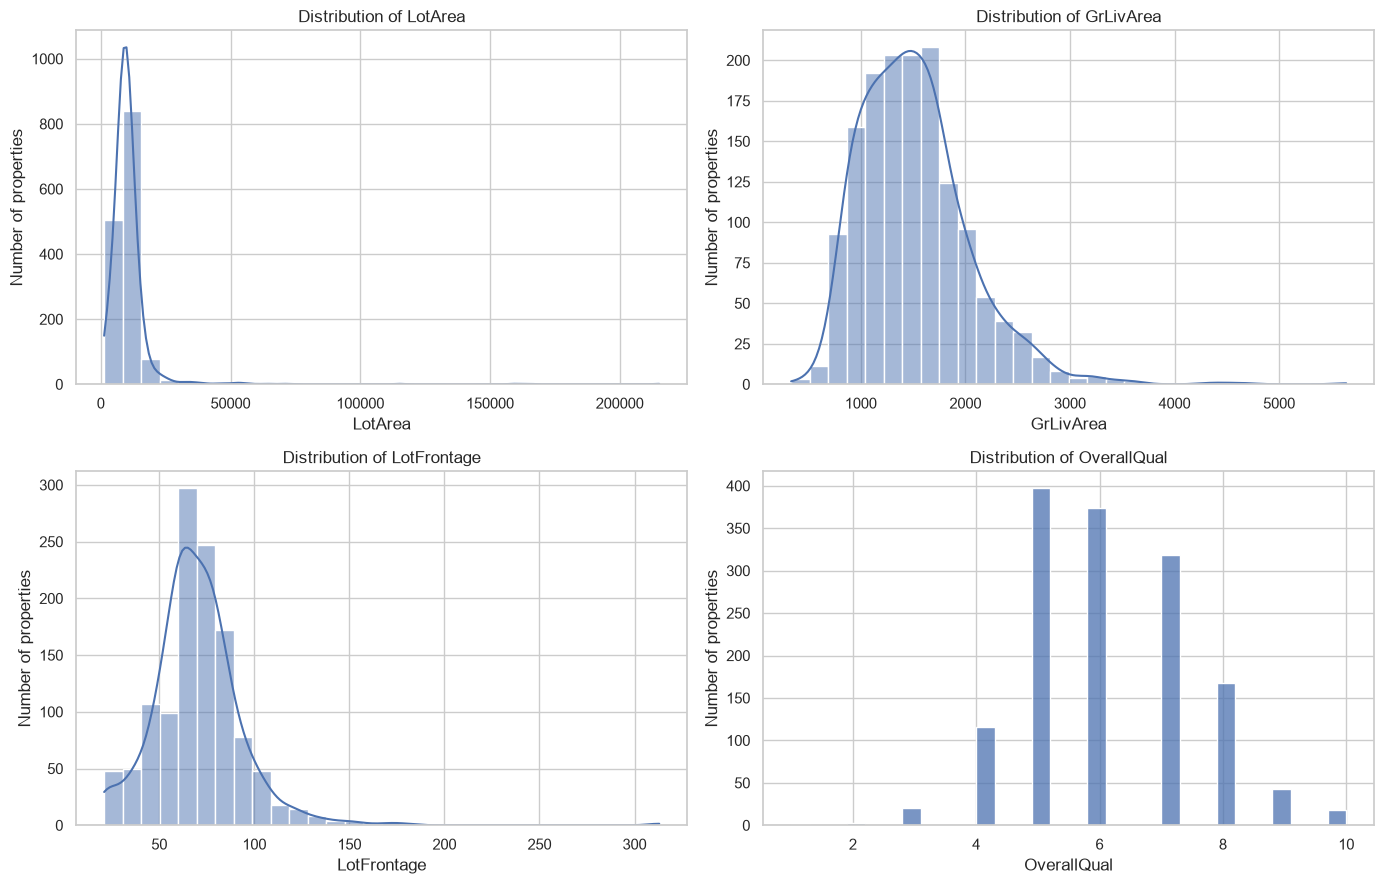

In [25]:
features_to_plot = [
    "LotArea",
    "GrLivArea",
    "LotFrontage",
    "OverallQual",
]

fig, axes = plt.subplots(2, 2, figsize=(14, 9))

for ax, feature in zip(axes.flat, features_to_plot):
    sns.histplot(
        data=df,
        x=feature,
        bins=30,
        kde=(feature != "OverallQual"),
        ax=ax,
    )
    ax.set_title(f"Distribution of {feature}")
    ax.set_xlabel(feature)
    ax.set_ylabel("Number of properties")

plt.tight_layout()
plt.show()

In [26]:
features_to_check = [
    "LotArea",
    "GrLivArea",
    "LotFrontage",
    "OverallQual",
]

distribution_summary = df[features_to_check].agg(
    ["mean", "median", "skew"]
).T

display(distribution_summary.round(3))

,mean,median,skew
LotArea,"10,516.83","9,478.50",12.21
GrLivArea,"1,515.46","1,464.00",1.37
LotFrontage,70.05,69.00,2.16
OverallQual,6.10,6.00,0.22


### Numerical Distribution and Skewness Findings

Skewness was calculated for four selected numerical predictors.

- `LotArea` has skewness of 12.21, indicating an extremely right-skewed distribution.
- `LotFrontage` has skewness of 2.16, indicating strong right skewness.
- `GrLivArea` has skewness of 1.37, indicating moderate right skewness.
- `OverallQual` has skewness of 0.22 and is approximately symmetric, although its values represent discrete ordinal ratings.

For `LotArea`, `GrLivArea`, and `LotFrontage`, the mean exceeds the median, consistent with the influence of larger observations.

**Modeling implication:** Retain the original features for baseline modeling. Evaluate transformations such as `log1p` for strongly skewed features using a consistent validation strategy. Do not remove observations or transform features solely because their distributions are skewed.

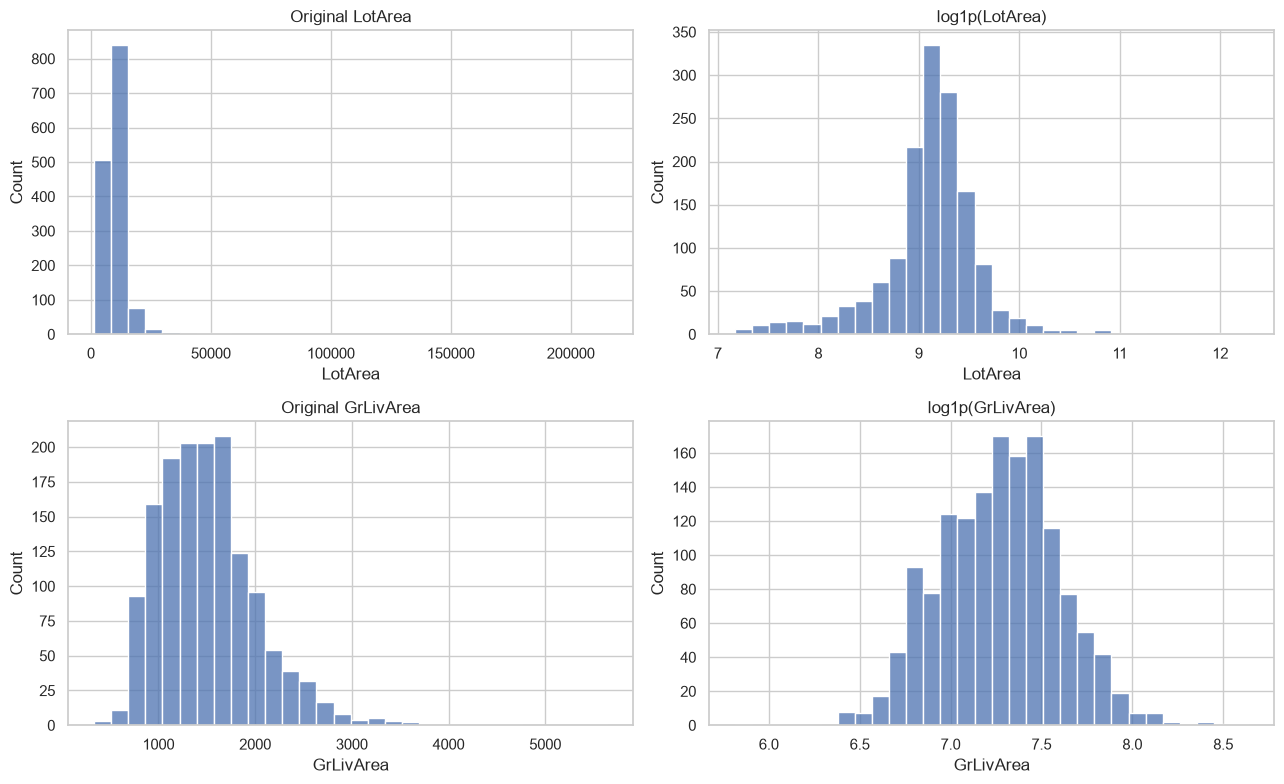

,original_skew,log1p_skew
LotArea,12.21,-0.14
GrLivArea,1.37,-0.01


In [27]:
features_to_transform_check = ["LotArea", "GrLivArea"]

fig, axes = plt.subplots(2, 2, figsize=(13, 8))

for row, feature in enumerate(features_to_transform_check):
    sns.histplot(df[feature], bins=30, ax=axes[row, 0])
    axes[row, 0].set_title(f"Original {feature}")

    sns.histplot(np.log1p(df[feature]), bins=30, ax=axes[row, 1])
    axes[row, 1].set_title(f"log1p({feature})")

plt.tight_layout()
plt.show()

skew_comparison = pd.DataFrame({
    "original_skew": df[features_to_transform_check].skew(),
    "log1p_skew": np.log1p(df[features_to_transform_check]).skew(),
})

display(skew_comparison.round(3))

### Log Transformation Experiment

The `log1p` transformation was evaluated for `LotArea` and `GrLivArea`.

| Feature | Original skewness | `log1p` skewness |
|---|---:|---:|
| `LotArea` | 12.21 | -0.14 |
| `GrLivArea` | 1.37 | -0.01 |

The transformation substantially reduced skewness in both features. `LotArea` changed from extremely right-skewed to approximately symmetric, while `GrLivArea` became approximately symmetric.

**Conclusion:** Log transformation is a promising experiment for these predictors. The original values will be retained in the raw dataset, and the effect of transformations will be evaluated through model validation rather than assumed from distribution shape alone.

,YearsSinceBuilt,YearsSinceRemodel,SalePrice
YearsSinceBuilt,1.00,0.59,-0.52
YearsSinceRemodel,0.59,1.00,-0.51
SalePrice,-0.52,-0.51,1.00


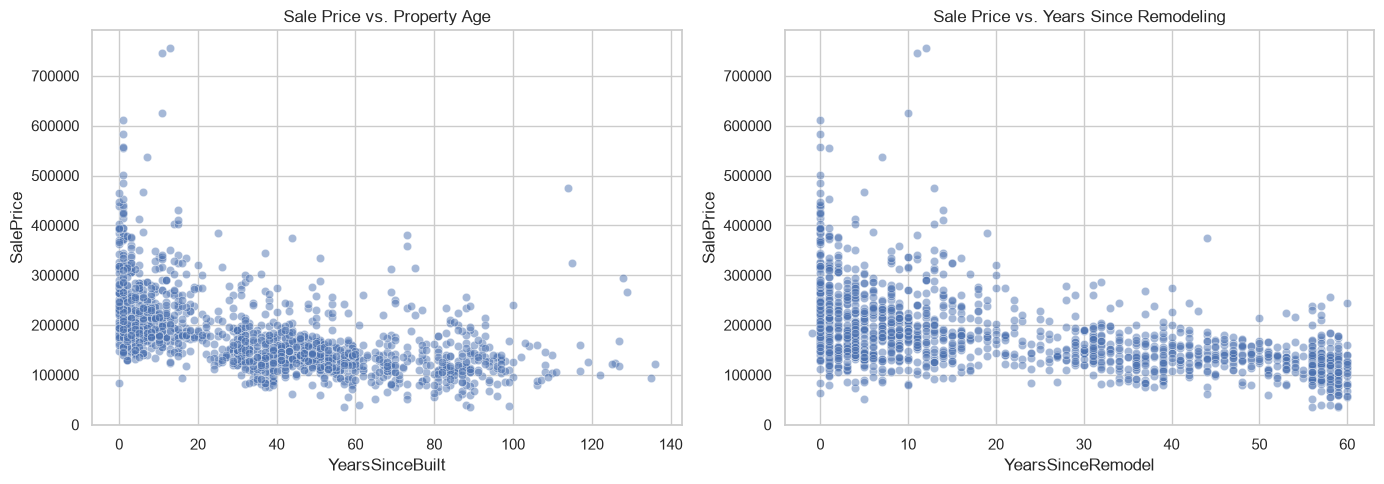

In [28]:
# Compare sale prices by construction year and remodeling history.
df["YearsSinceBuilt"] = df["YrSold"] - df["YearBuilt"]
df["YearsSinceRemodel"] = df["YrSold"] - df["YearRemodAdd"]

age_summary = df[
    ["YearsSinceBuilt", "YearsSinceRemodel", "SalePrice"]
].corr()

display(age_summary.round(3))

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.scatterplot(
    data=df,
    x="YearsSinceBuilt",
    y="SalePrice",
    alpha=0.5,
    ax=axes[0],
)
axes[0].set_title("Sale Price vs. Property Age")

sns.scatterplot(
    data=df,
    x="YearsSinceRemodel",
    y="SalePrice",
    alpha=0.5,
    ax=axes[1],
)
axes[1].set_title("Sale Price vs. Years Since Remodeling")

plt.tight_layout()
plt.show()

### Property Age and Renovation Analysis

Two derived features were explored:

- `YearsSinceBuilt = YrSold - YearBuilt`
- `YearsSinceRemodel = YrSold - YearRemodAdd`

Their correlations with `SalePrice` were:

| Feature | Correlation with SalePrice |
|---|---:|
| YearsSinceBuilt | -0.52 |
| YearsSinceRemodel | -0.51 |

Both features have moderate negative correlations with sale price. This suggests that properties with more years since construction or remodeling tend to have lower sale prices in this dataset.

The two age-related features have a correlation of 0.59, indicating that they share some information but are not identical.

**Conclusion:** Age-related features are candidates for model experimentation. Their usefulness should be assessed through validation, alongside original year features and property-quality information. Correlation alone does not establish causation or guarantee improved predictive accuracy.

,count,median,mean
PropertyAgeGroup,,,
0–10 years,434,"219,355.00","238,951.72"
11–30 years,208,"189,000.00","212,072.16"
31–50 years,379,"145,000.00","152,208.77"
51–100 years,411,"127,000.00","132,249.30"
Over 100 years,28,"123,250.00","153,118.04"


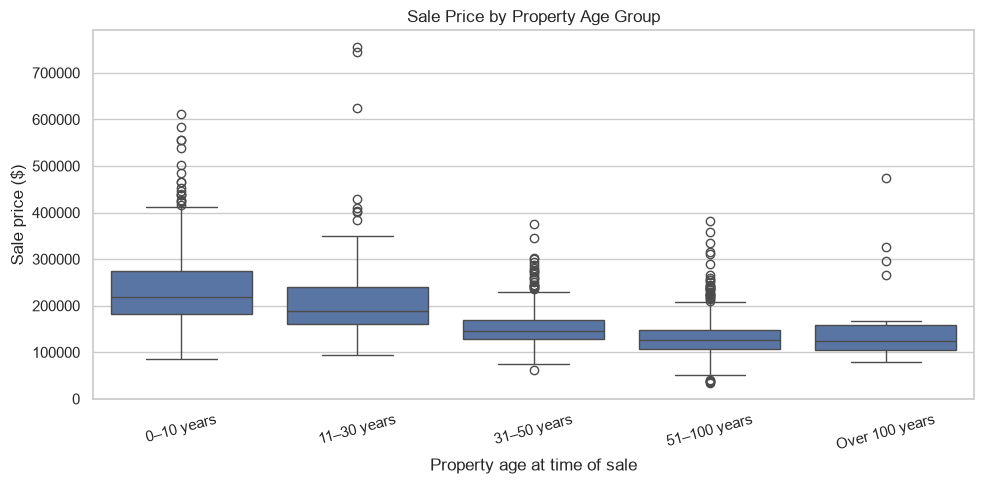

In [29]:
# Create age groups for descriptive analysis only.
age_bins = [-1, 10, 30, 50, 100, float("inf")]
age_labels = [
    "0–10 years",
    "11–30 years",
    "31–50 years",
    "51–100 years",
    "Over 100 years",
]

df["PropertyAgeGroup"] = pd.cut(
    df["YearsSinceBuilt"],
    bins=age_bins,
    labels=age_labels,
)

age_group_summary = (
    df.groupby("PropertyAgeGroup", observed=False)["SalePrice"]
    .agg(["count", "median", "mean"])
)

display(age_group_summary.round(2))

plt.figure(figsize=(10, 5))
sns.boxplot(
    data=df,
    x="PropertyAgeGroup",
    y="SalePrice",
)
plt.title("Sale Price by Property Age Group")
plt.xlabel("Property age at time of sale")
plt.ylabel("Sale price ($)")
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()

### Sale Price by Property Age Group

Properties were grouped by their age at the time of sale for descriptive analysis.

- Homes aged 0–10 years had the highest median sale price ($219,355).
- Median sale price generally decreased across older age groups, reaching $127,000 for homes aged 51–100 years.
- Homes over 100 years old had a median of $123,250 and a mean of $153,118.04. The difference between the mean and median suggests that some higher-priced properties influence this group's average.
- The oldest group contains only 28 observations, so its summary should be interpreted cautiously.

**Conclusion:** Property age is a potentially useful predictor, but its relationship with price may also reflect neighborhood, quality, size, and renovation history. These factors should be considered together during modeling.

In [30]:
selected_neighborhoods = (
    df.groupby("Neighborhood")["SalePrice"]
    .median()
    .sort_values(ascending=False)
    .head(5)
    .index
)

neighborhood_age_summary = (
    df[df["Neighborhood"].isin(selected_neighborhoods)]
    .groupby(["Neighborhood", "PropertyAgeGroup"], observed=True)["SalePrice"]
    .agg(["count", "median"])
    .reset_index()
    .sort_values(["Neighborhood", "PropertyAgeGroup"])
)

display(neighborhood_age_summary.round(2))

,Neighborhood,PropertyAgeGroup,count,median
0,NoRidge,0–10 years,8,"297,500.00"
1,NoRidge,11–30 years,33,"301,500.00"
2,NridgHt,0–10 years,77,"315,000.00"
3,Somerst,0–10 years,85,"226,000.00"
4,Somerst,11–30 years,1,"155,000.00"
5,StoneBr,0–10 years,16,"367,209.50"
6,StoneBr,11–30 years,9,"207,500.00"
7,Timber,0–10 years,21,"269,500.00"
8,Timber,11–30 years,10,"185,750.00"
9,Timber,31–50 years,5,"228,950.00"


### Neighborhood and Property Age Interaction

Property-age comparisons within selected high-median-price neighborhoods reveal different patterns.

- In StoneBr, homes aged 0–10 years have a median sale price of $367,209.50, compared with $207,500 for homes aged 11–30 years.
- In NoRidge, the corresponding medians are $297,500 and $301,500, showing little difference between these two groups.
- Timber has limited observations in its older age groups, and Somerst has only one home in the 11–30-year group.
- All 77 selected NridgHt observations fall in the 0–10-year group in this summary.

**Conclusion:** The relationship between age and sale price varies across neighborhoods. Small group sizes limit some comparisons. Neighborhood and property age should therefore be considered together during exploratory analysis and model evaluation, without assuming a causal relationship.

,correlation
OverallQual,0.79
GrLivArea,0.71
GarageCars,0.64
GarageArea,0.62
TotalBsmtSF,0.61
1stFlrSF,0.61
FullBath,0.56
TotRmsAbvGrd,0.53
YearsSinceBuilt,-0.52
YearBuilt,0.52


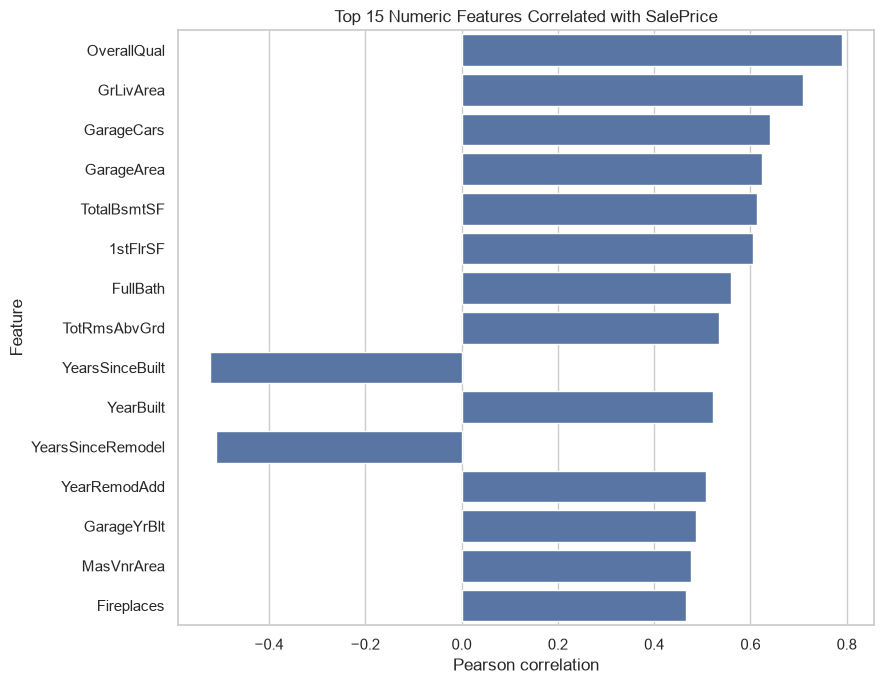

In [31]:
# Correlations between numeric predictors and SalePrice.
# Exclude the identifier and temporary categorical age-group column.
numeric_df = df.select_dtypes(include=["number"]).drop(
    columns=["Id"],
    errors="ignore",
)

saleprice_correlations = (
    numeric_df.corr(numeric_only=True)["SalePrice"]
    .drop("SalePrice")
    .sort_values(key=abs, ascending=False)
)

display(saleprice_correlations.head(15).to_frame("correlation").round(3))

plt.figure(figsize=(9, 7))
sns.barplot(
    x=saleprice_correlations.head(15).values,
    y=saleprice_correlations.head(15).index,
)
plt.title("Top 15 Numeric Features Correlated with SalePrice")
plt.xlabel("Pearson correlation")
plt.ylabel("Feature")
plt.tight_layout()
plt.show()

### Correlation Analysis: Most Promising Numerical Predictors

The strongest positive Pearson correlations with `SalePrice` include:

- `OverallQual`: 0.79
- `GrLivArea`: 0.71
- `GarageCars`: 0.64
- `GarageArea`: 0.62
- `TotalBsmtSF`: 0.61
- `1stFlrSF`: 0.61

Other notable relationships include `FullBath` (0.56), `TotRmsAbvGrd` (0.53), and `YearBuilt` (0.52). The derived feature `YearsSinceBuilt` has a negative correlation of -0.52, while `YearsSinceRemodel` has a correlation of -0.51.

**Interpretation:** Overall quality and above-ground living area have the strongest linear relationships with sale price among the examined numerical features. Garage capacity, basement area, first-floor area, bathrooms, and property age are also promising predictors.

**Limitations:** Correlation does not establish causation, and Pearson correlation may not capture nonlinear relationships. Related features may contain overlapping information. Feature usefulness will ultimately be evaluated through validation and model comparison.